<center><img src="https://gitlab.com/accredian/insaid-data/-/raw/main/Logo-Accredian/Case-Study-Cropped.png" width= 30% /></center>

# <center><b>ECOMM: Carnival Sale Day Case Study<b></center>

---
# **Table of Contents**
---
**1.** [**Introduction**](#Section1)<br>
**2.** [**Problem Statement**](#Section2)<br>
**3.** [**Installing & Importing Libraries**](#Section3)<br>

  - **3.1** [**Installing Libraries**](#Section31)

  - **3.2** [**Upgrading Libraries**](#Section32)

  - **3.3** [**Importing Libraries**](#Section33)

**4.** [**Data Acquisition & Description**](#Section4)<br>

  - **4.1** [**Data Description**](#Section41)

  - **4.2** [**Data Information**](#Section42)

**5.** [**Data Pre-Profiling**](#Section5)<br>

**6.** [**Data Pre-processing**](#Section6)<br>

  - **6.1** [**Handling of Missing Data**](#Section61)

  - **6.2** [**Handling of Useless Features**](#Section62)

  - **6.3** [**Handling of Inconsistent Data**](#Section63)

  - **6.4** [**Handling of Non-standardized Data**](#Section64)

  - **6.5** [**Handling of Outliers**](#Section65)

**7.** [**Exploratory Data Analysis**](#Section6)<br>

**8.** [**Conclusion**](#Section8)<br>





<a id = Section1></a>

---
# **1. Introduction**
---

* **ECOMM** Private Limited is an Indian **e-commerce** company headquartered in **Delhi**, incorporated in Singapore as a private limited company.
* ECOMM was founded in 2007 to make **shopping** easy and hassle-free for
people, allowing them to order products without ever leaving their houses.
*ECOMM held **39.5%** of India's e-commerce market share in **March 2017**. There is a dominating position for ECOMM in the **apparel** industry
* Big Billion Days are one of India's most notable **annual e-commerce sales**, where ECOMM offers **heavy discounts** on electronic devices, clothing, footwear, furniture, cosmetics, F&B, and more.

<br>

<center><img src="https://preview.redd.it/zkrlhe41kh481.jpg?width=640&crop=smart&auto=webp&s=6893a1b632bd394e73bcdb8e34dcdcd9114ab9ca" width="600" height="310" /></center>


<a id = Section2></a>

---
# **2. Problem Statement**
---


* ECOMM has provided a **summary** of the purchases made by different customers for selected products with **high sales** in the last month.
* The dataset also includes **customer demographics** (age, gender, marital status, city type, location), product details (product ID and product category), and total purchase amount for the last month.
* You are a **data scientist** working at ECOMM and as part of ECOMM's **customer retention** and **profitability strategy**, the company wants to understand the **purchase behavior** of its customers based on factors such as age, gender,occupation and:
  - **Categorize** them based on their purchases.
 - Assign **delivery partners** in the right area.
 - **Stock** the best selling products for the **big billion day sale.**
 - Provide **personalized offers**.

<a id = Section3></a>

---
# **3. Installing & Importing Libraries**
---

<a id = Section31></a>
### **3.1 Installing Libraries**

In [74]:
# #-----------------------------------------------------------------------------------------------------------------------#
# !pip install -q datascience                                                # Package that is required by pandas profiling
# !pip install -q ydata-profiling                                           # Toolbox for Generating Statistics Report
# #-----------------------------------------------------------------------------------------------------------------------#

<a id = Section32></a>
### **3.2 Upgrading Libraries**


In [75]:
# !pip install -q --upgrade pandas-profiling
# !pip install -q --upgrade yellowbrick

In [76]:
#-------------------------------------------------------------------------------------------------------------------------------
import numpy as np                                                  # To perform numerical operations
import pandas as pd                                                 # Importing for panel data analysis
from ydata_profiling import ProfileReport                          # Importing Pandas Profiling
pd.set_option('display.max_columns', None)                          # Unfolding hidden features if the cardinality is high
pd.set_option('display.max_colwidth', None)                         # Unfolding the max feature width for better clearity
pd.set_option('display.max_rows', 100)                             # Unfolding hidden data points if the cardinality is high
pd.set_option('mode.chained_assignment', None)                      # Removing restriction over chained assignments operations
pd.set_option('display.float_format', lambda x: '%.5f' % x)         # To suppress scientific notation over exponential values

#-------------------------------------------------------------------------------------------------------------------------------
import matplotlib.pyplot as plt                                     # Importing pyplot interface using matplotlib
import seaborn as sns                                               # Importin seaborm library for visualization
sns.set_theme(style="white", palette="muted")
%matplotlib inline
#-------------------------------------------------------------------------------------------------------------------------------
import warnings                                                     # Importing warning to disable runtime warnings
warnings.filterwarnings("ignore")                                   # Warnings will appear only once

<a id = Section4></a>

---
# **4. Data Acquisition & Description**
---



**Acquisition:**

- data was collected from ECOMM database 1 month before big billion day sale.
- occupation and product categories are masked to protect the vital information.

<br>

| Records | Features | Dataset Size |
| :-- | :-- | :-- |
| 203281 | 12 | 24.3 MB|

<br>

|Id|Features|Description|
| :-- | :-- | :-- |
|01|**User_ID**|Unique ID for each user.|
|02|**Product_ID**|Unique ID for each product.|
|03|**Gender**|Gender of the user(M/F).|
|04|**Age**|Age of the user.|
|05|**Occupation**|Occupation.|
|06|**City_Category**|Category of the city(Type B/Type C/Other).|
|07|**Current_City_Years**|Number of years stayed in the current city.|
|08|**Marital_Status**|Marital Status(0 - Married/1 - Unmarried).|
|09|**Product_Category**|Category of the Product Purchased(1 - 18)|
|12|**Purchase**|purchase amount in  ₹.|

<br>

In [77]:
# Path to the dataset
path = "https://gitlab.com/accredian/insaid-data/-/raw/main/Terms%202023/Term%203%20EDA/ECOMM_Dataset.csv"

# Reading the Data
df = pd.read_csv(path)

In [78]:
df.head()

,UserID,ProductID,Gender,Age,Occupation,City_Category,Current_City_Years,Marital_Status,Product_Category,Purchase
0,1000001,P00069042,F,0-17,engineer,A,2,0,3.00000,8370
1,1000001,P00248942,F,0-17,engineer,A,2,0,1.00000,15200
2,1000001,P00087842,F,0-17,engineer,A,2,0,12.00000,1422
3,1000001,P00085442,F,0-17,engineer,A,2,0,12.00000,1057
4,1000002,P00285442,M,55+,Bank Manager,C,4+,0,8.00000,7969


<a id = Section41></a>
### **4.1 Data Description**

- In this section we will get **information about the data** and see some observations.


In [79]:
df.describe()

,UserID,Marital_Status,Product_Category,Purchase
count,240882.00000,240882.00000,240691.00000,240882.00000
mean,1002928.64925,0.41051,5.29080,9314.30304
std,1758.36149,0.49193,3.74460,4974.43815
min,1000001.00000,0.00000,1.00000,185.00000
25%,1001327.00000,0.00000,1.00000,5856.00000
50%,1002935.00000,0.00000,5.00000,8057.00000
75%,1004418.00000,1.00000,8.00000,12060.00000
max,1006040.00000,1.00000,18.00000,23961.00000


**Observation:**
- Average Purchase price is around **₹9300**
- Minimum Purchase price is **₹185** and Maximum is around **₹24000**

<a name = Section42></a>
### **4.2 Data Information**

- In this section we will see the **information about the types of features**.

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240882 entries, 0 to 240881
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   UserID              240882 non-null  int64  
 1   ProductID           240882 non-null  object 
 2   Gender              240741 non-null  object 
 3   Age                 240882 non-null  object 
 4   Occupation          240882 non-null  object 
 5   City_Category       240794 non-null  object 
 6   Current_City_Years  240882 non-null  object 
 7   Marital_Status      240882 non-null  int64  
 8   Product_Category    240691 non-null  float64
 9   Purchase            240882 non-null  int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 18.4+ MB


**Observations:**

- At high level, we can observe that there are **missing data** in our dataset.

<a name = Section5></a>

---
# **5. Data Pre-Profiling**
---

<a name = Section51></a>
### **5.1 Pre Profiling Report**

- For **quick analysis** pandas profiling is very handy.

- Generates profile reports from a pandas DataFrame.

- For each column **statistics** are presented in an interactive HTML report.

In [87]:
from ydata_profiling import ProfileReport

In [88]:
profile = ProfileReport(df=df)
profile.to_file(output_file='Pre Profiling Report.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [8]:
#from google.colab import files                   # Use only if you are using Google Colab, otherwise remove it
#files.download('Pre Profiling Report.html')      # Use only if you are using Google Colab, otherwise remove it

**Observation:**
- According to the report there are around **10 columns.**
- There are around **37606(15.6) Duplicated Rows** in the Data
- A Total of **425 Cells** are missing.

<a id = Section6></a>

---
# **6. Data Pre-Processing**
---

- In this section, we will perform the **cleaning** operations over the features using information from the previous section.

<a name = Section61></a>
### **6.1 Handling Duplicated Data**

- From the **Pre Profiling Report**, we know that there is some duplicacy in the rows of the dataset.

In [18]:
# Checking for Duplicacy
print('Number of Duplicated Rows in the dataset:', df.duplicated().sum())

Number of Duplicated Rows in the dataset: 0


**Observation:**

- There a total of **37605 Duplicated Rows** in the dataset.

- Since Duplicated rows does **not provide any new information** to us and it only **increases the processing time** for our code, we'll simply **drop all the duplicated rows.**

In [19]:
# Before Operation
print('Number of rows before removing duplicates:', df.shape[0])

# Dropping Duplicates
df = (df
      .drop_duplicates()
      .reset_index(drop=True))
print('Operation Complete')

# After Operation
print('Number of rows after removing duplicates:', df.shape[0])

Number of rows before removing duplicates: 203277
Operation Complete
Number of rows after removing duplicates: 203277


**Observation:**

- All the **Duplicated rows has been removed** from the dataset.

<a name = Section62></a>
### **6.2 Handling of Missing Data**

- In this section we will see if we can **fill** the missing data with some **logical imputation.**

In [20]:
category_cols = df.select_dtypes('object').columns

for col in category_cols:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)

In [21]:
num_cols = df.select_dtypes(['float', 'int']).columns

for col in num_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

In [22]:
# Cross-Checking the Operations
df.isnull().sum()

UserID                0
ProductID             0
Gender                0
Age                   0
Occupation            0
City_Category         0
Current_City_Years    0
Marital_Status        0
Product_Category      0
Purchase              0
dtype: int64

**Observation:**

- Missing Values in the **Gender and City_category** has been **Filled Successfully.**

- Now, to fill the missing values in **Product_Category**:

    - We have **Product ID** in the dataset, so we can use that information to fill the missing values in **Product_Category.**

    - First create a **Dictionary** that **maps** every **Product_ID** to it\'s **corresponding Product_Category.**

    - Use that **Dictionary to fill the missing Product_Category** if that product was ordered in any of the rest of the purchases.

    - Finally **drop any rows** in which **we can not fill Product_Category** using the above described method.

In [9]:
df

,UserID,ProductID,Gender,Age,Occupation,City_Category,Current_City_Years,Marital_Status,Product_Category,Purchase
0,1000001,P00069042,F,0-17,engineer,A,2,0,3.0,8370
1,1000001,P00248942,F,0-17,engineer,A,2,0,1.0,15200
2,1000001,P00087842,F,0-17,engineer,A,2,0,12.0,1422
3,1000001,P00085442,F,0-17,engineer,A,2,0,12.0,1057
4,1000002,P00285442,M,55+,Bank Manager,C,4+,0,8.0,7969
...,...,...,...,...,...,...,...,...,...,...
203272,1001365,P00271142,F,0-17,engineer,C,3,0,5.0,5210
203273,1001365,P00251242,F,0-17,engineer,C,3,0,5.0,5385
203274,1001366,P00184942,M,0-17,engineer,C,0,0,1.0,15573
203275,1001366,P00237642,M,0-17,engineer,C,0,0,5.0,5262


**Observation:**

- All the **Missing values in the Product Category has been filled** using the information of ProductID

<a id = Section6></a>

---
# **6. Exploratory Data Analysis**
---

**<h4>Question 1: Which Age group has the highest pruchase level on ECOMM's Website?</h4>**




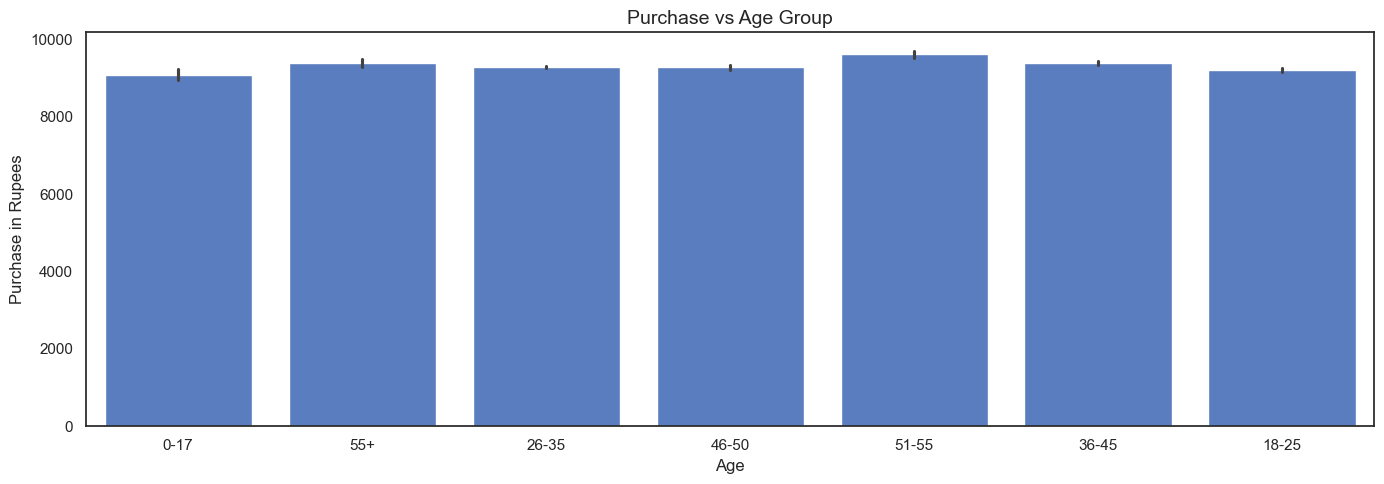

In [28]:
# Canvas
fig, ax = plt.subplots(figsize=(14,5))

# Plotting
sns.barplot(data = df, x = 'Age',y = 'Purchase', ax=ax, estimator='mean')
plt.title('Purchase vs Age Group', size=14)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Purchase in Rupees", fontsize=12)
plt.tight_layout()

**Observation:**

- People **above 50 years** of age spend more money on online shopping


**<h4>Question 2: Which Age group is the most frequent on the platform?</h4>**

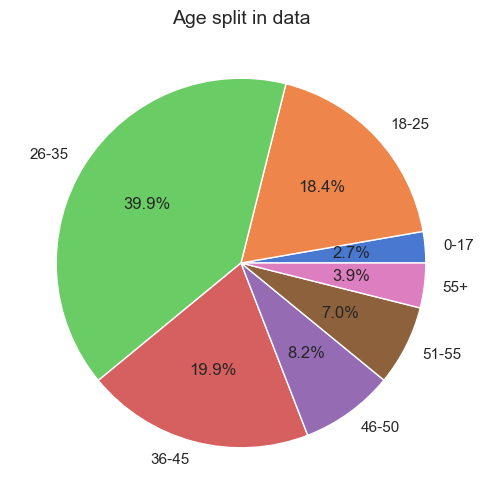

In [31]:
# Canvas
fig, ax = plt.subplots(figsize=(6, 6))

data_Age = df.groupby('Age')['Age'].count()
data_Age = pd.DataFrame({'Age':data_Age.index, 'Count':data_Age.values})

# Plotting
plt.pie(x=data_Age['Count'],labels = data_Age['Age'],autopct='%1.1f%%')
plt.title('Age split in data', fontsize=14);

**Observation:**

- According to the pie-chart, most of the people visiting the store are **adults** (25 - 45).
- The most Frequent Age Group is **(26 - 35) at 40%**
- And the least Frequent Age Group is **(0 - 17) at 2.7%**

**<h4>Question 3: Which gender shops more on ECOMM?</h4>**




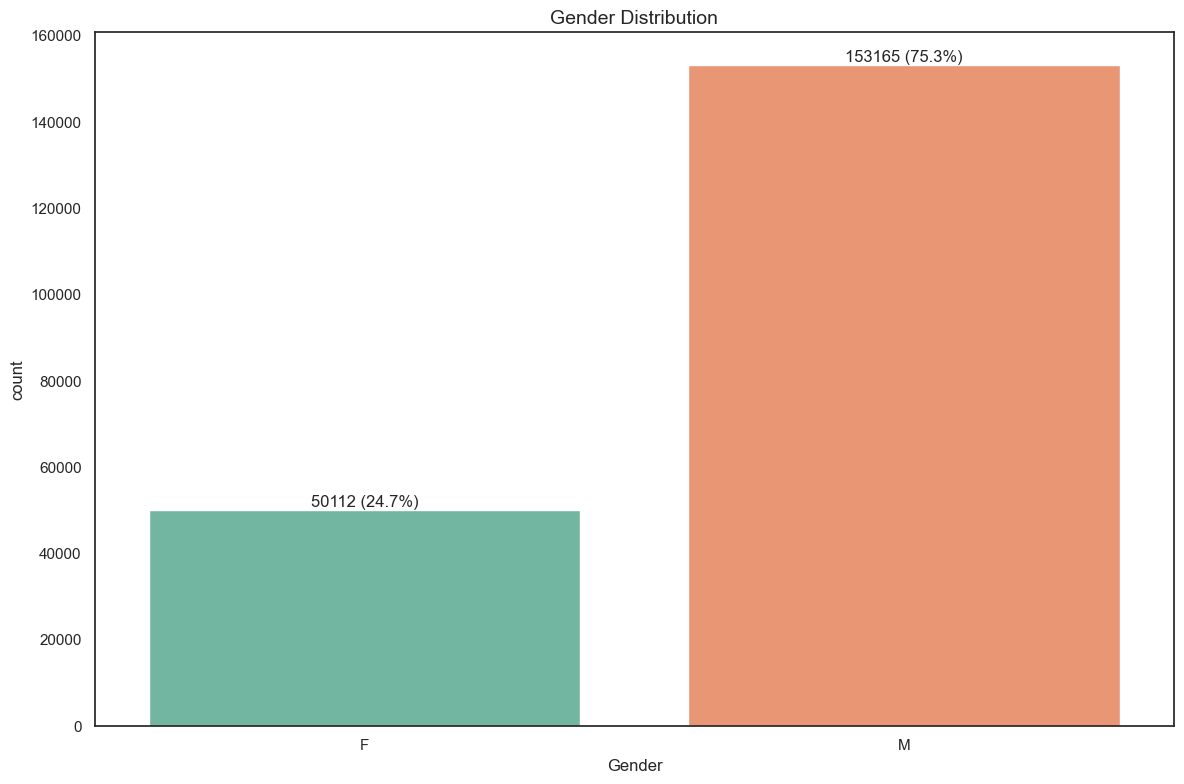

In [37]:
# Canvas
fig, ax = plt.subplots(figsize=(12,8))

# Plot
sns.countplot(x='Gender', data=df, palette='Set2', ax=ax)
for p in plt.gca().patches:
    x=p.get_bbox().get_points()[:,0]
    y=p.get_bbox().get_points()[1,1]
    value = f"{round(y)} ({round((y/df.shape[0])*100, 1)}%)"
    ax.annotate(value, 
                xy=(x.mean(), y),
                ha='center', 
                va='bottom', 
                size=12)

plt.title('Gender Distribution', fontsize=14)
plt.tight_layout()

**Observation:**

- We can observe that ECOMM's majority customer base is **Male** (75%)


**<h4>Question 4: Which category does the majority of the occupation fall into? </h4>**

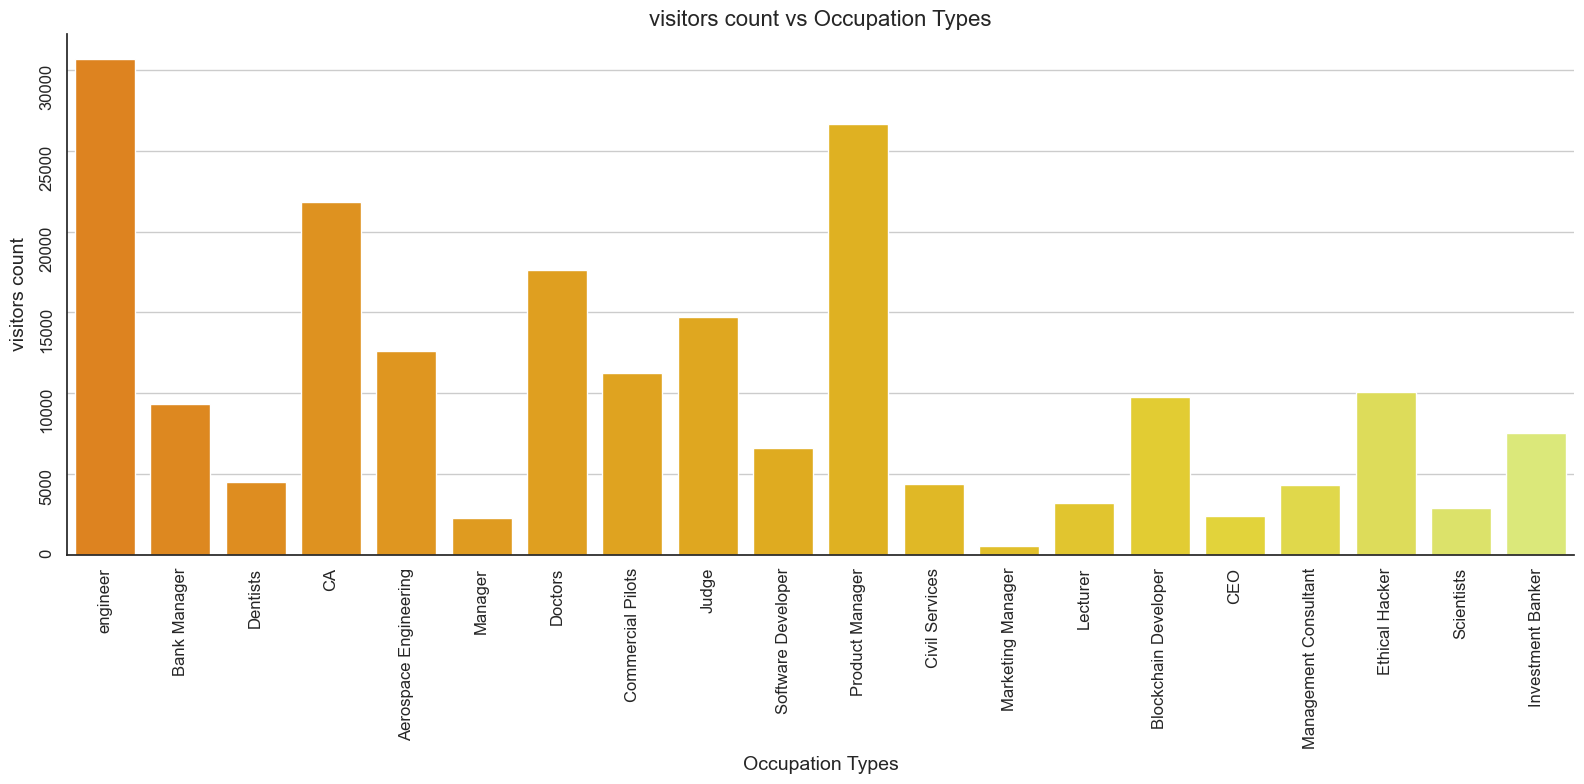

In [38]:
# Canvas
fig, ax  = plt.subplots(figsize=(16,8))

# Plot
sns.countplot(data=df, x='Occupation', palette='Wistia_r')
sns.despine();

# Aesthetics
plt.tick_params(rotation=90, labelsize=12)
plt.xlabel('Occupation Types', fontsize=14, labelpad=5)
plt.ylabel('visitors count', fontsize=14, labelpad=8)
plt.title('visitors count vs Occupation Types', fontsize=16);
plt.grid(axis='y')
plt.tight_layout()

**Observation:**
- **Engineers, Product Managers, and CAs** have the **highest** site visit count
- **lowest** site visit count is from **Marketing managers**


**<h4>Question 5: Which occupation group spend most on ECOMM?</h4>**


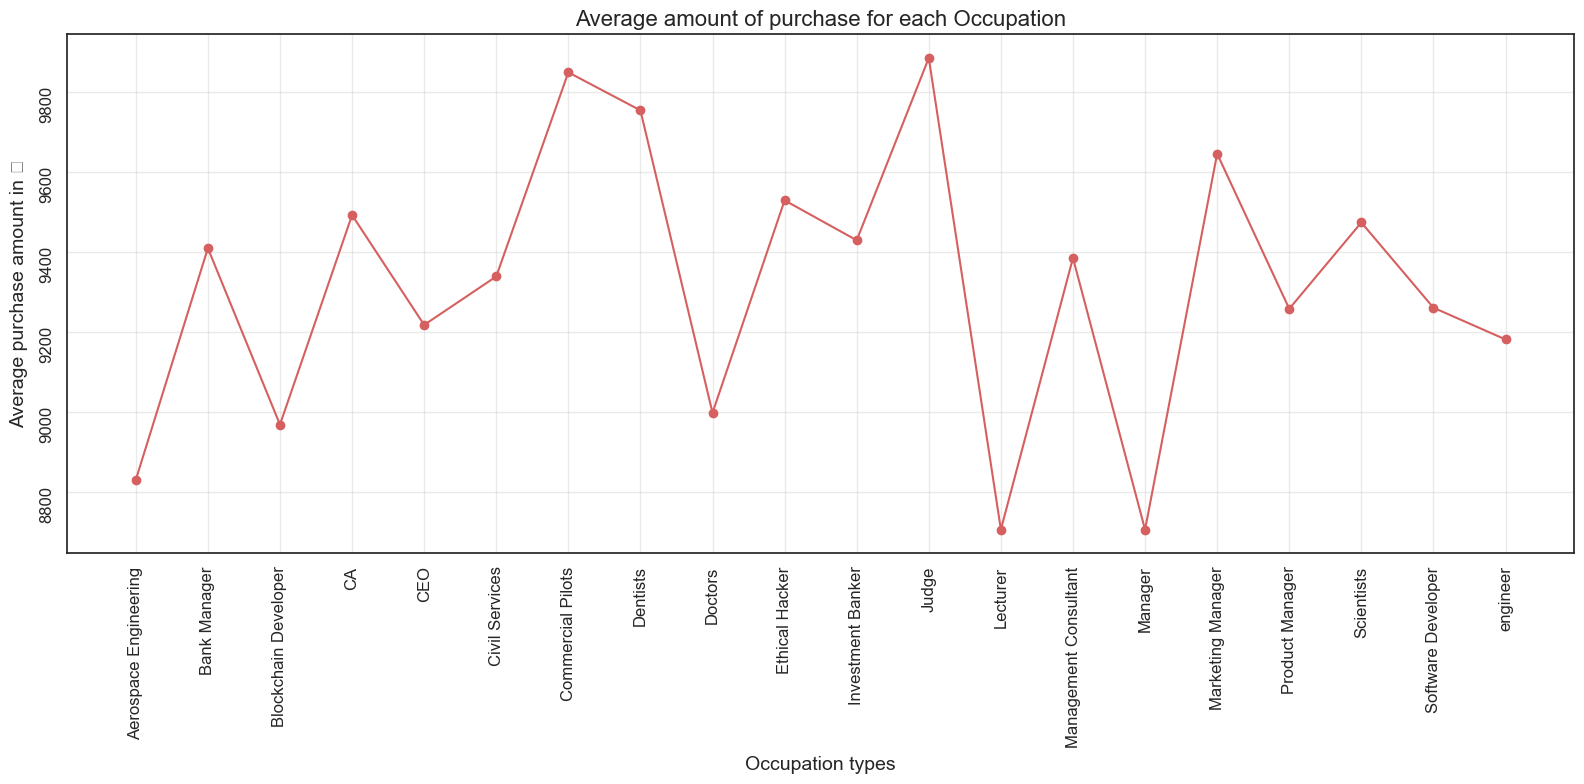

In [39]:
# Canvas
fig, ax = plt.subplots(figsize=(16,8))

# Plot
data = df.groupby('Occupation')['Purchase'].mean()
plt.plot(data.index, data.values ,'ro-')
plt.xlabel('Occupation types', fontsize=14, labelpad=6)
plt.ylabel('Average purchase amount in ₹', fontsize=14, labelpad=8)
plt.title('Average amount of purchase for each Occupation', fontsize=16)

# Aesthetics
plt.xticks(data.index)
plt.tick_params(rotation=90, labelsize=12)
plt.grid(alpha=0.4);
plt.tight_layout()

**Observation:**
- On average, people who are working as **Commercial Pilots,Dentists and Investment bankers** spends **more** money
- On average, people who are working as  **Lecturer and Manager** spend less money.

**<h4>Question 6: Top 10 products which made highest sales in the previous month?</h4>**

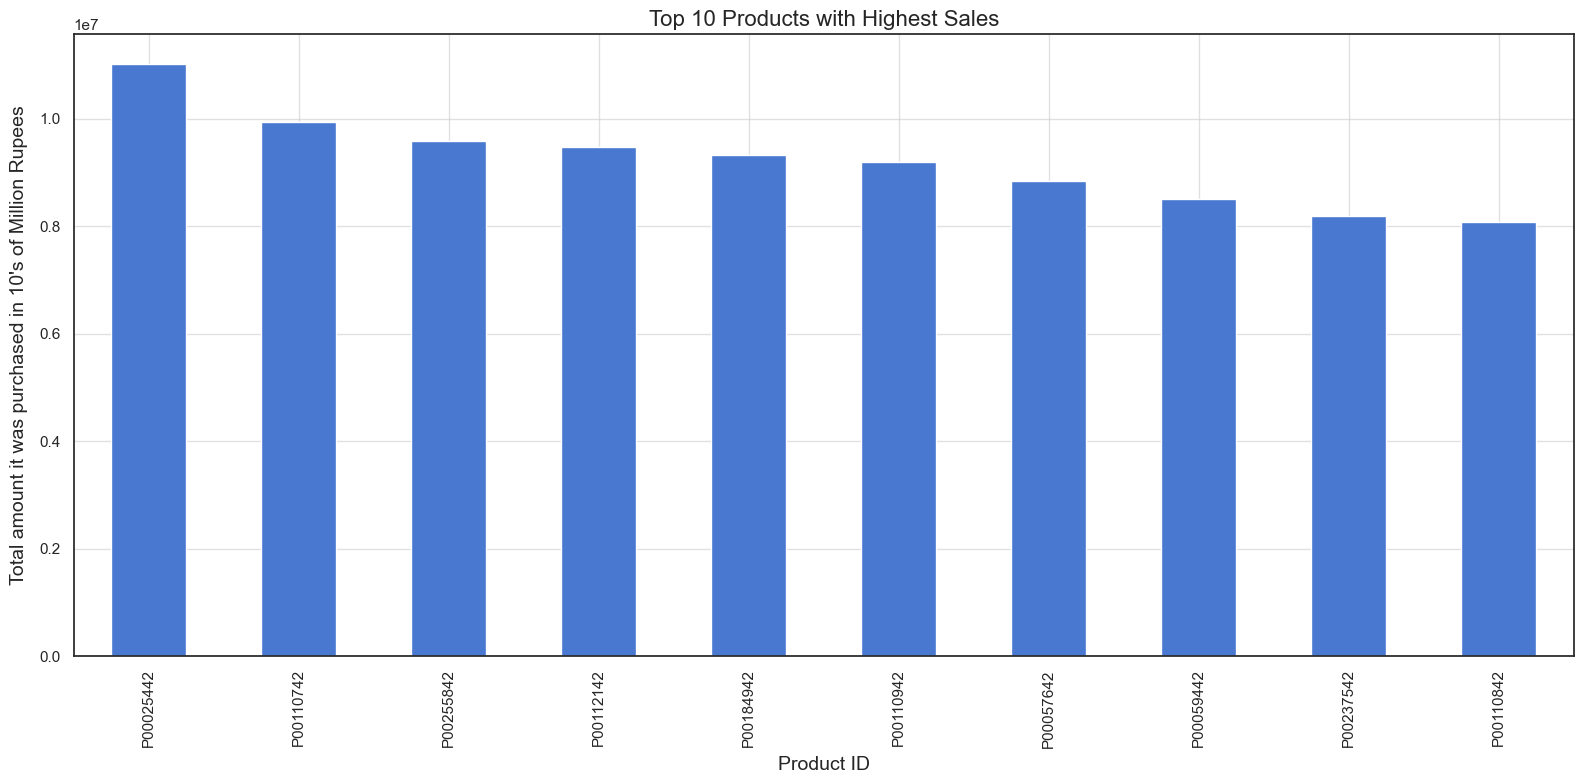

In [48]:
# Calculating Top 10
Top10_Products = df.groupby('ProductID').sum().sort_values(by='Purchase', ascending=False)[:10]

# Canvas
fig, ax = plt.subplots(figsize=(16,8))

# Plot
Top10_Products['Purchase'].plot.bar(ax=ax)
plt.xlabel('Product ID', fontsize=14, labelpad=6)
plt.ylabel('Total amount it was purchased in 10\'s of Million Rupees', fontsize=14, labelpad=8)
plt.title('Top 10 Products with Highest Sales', fontsize=16)

# Aesthetics
plt.grid(alpha=0.6)
plt.tight_layout()

**Observation:**

- Product **"P00025442"** has the **Highest Sales** on the ECOMM Platform.

- Followed by:

  - **"P00110742"**
  - **"P00255842"**
  - **"P00112142"**

**<h4>Question 7: Where are the most visitors coming from ?</h4>**

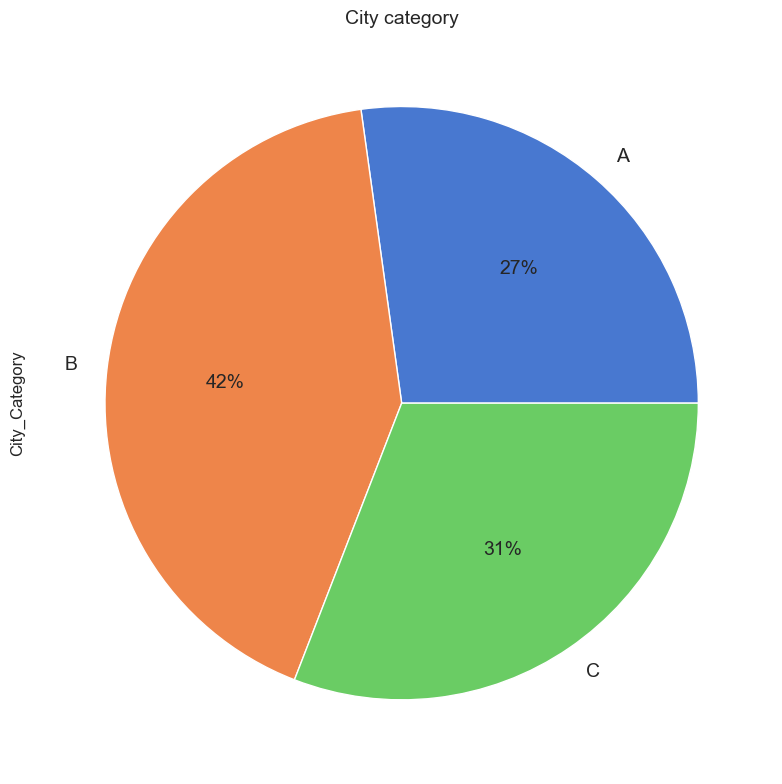

In [47]:
# Canvas
fig, ax = plt.subplots(figsize=(16,8))

# Print Data
b=df.groupby('City_Category')['City_Category'].agg('count')
print('\n\n')

# Plot
plt.title('City category', fontsize=14)

b.plot.pie(labels=b.index, 
           autopct='%.0f%%',
           wedgeprops={'edgecolor': 'white'},
           pctdistance=0.6, 
           textprops={'size':14})
plt.tight_layout()

**Observation:**

- The **Majority** of the users come from **City Category B at 42%.**

- While the **City Category A**, contains only **27% of our customer** base.

**<h4>Question 8: Marital status status of the visitors?</h4>**

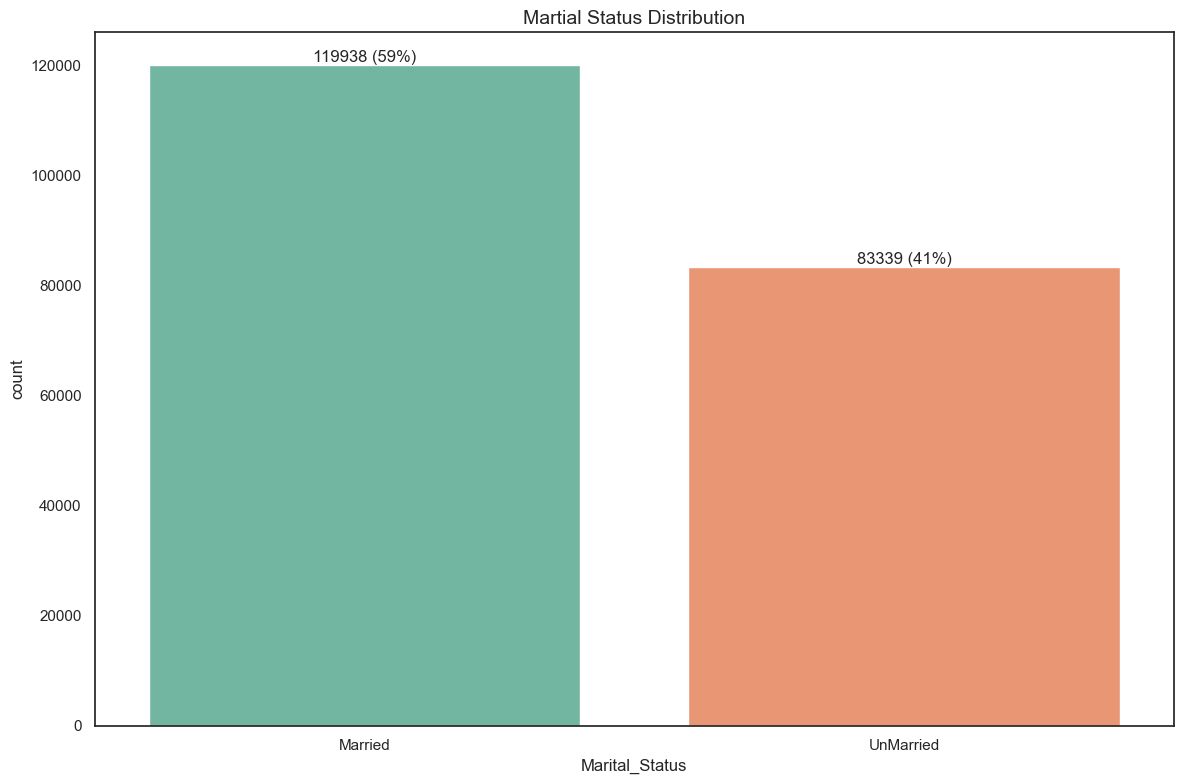

In [52]:
# Canvas
fig, ax = plt.subplots(figsize=(12,8))

# Plot
sns.countplot(data=df, x='Marital_Status', palette='Set2' ,ax=ax)
for p in plt.gca().patches:
    x=p.get_bbox().get_points()[:,0]
    y=p.get_bbox().get_points()[1,1]
    value = f"{round(y)} ({round((y/df.shape[0])*100)}%)"
    ax.annotate(text=value, 
                xy=(x.mean(), y),
                ha='center', 
                va='bottom', 
                size=12)
plt.xticks([0,1], ['Married', 'UnMarried'])
plt.title('Martial Status Distribution', fontsize=14)
plt.tight_layout()

**Observation:**

- People visting the store are **married** and has **higher** count as compared to **singles**.
- **Married Customers** makes up of **more than half of our customer base (59%)**

**<h4>Question 9: Check the Distribution of Purchase Price?</h4>**

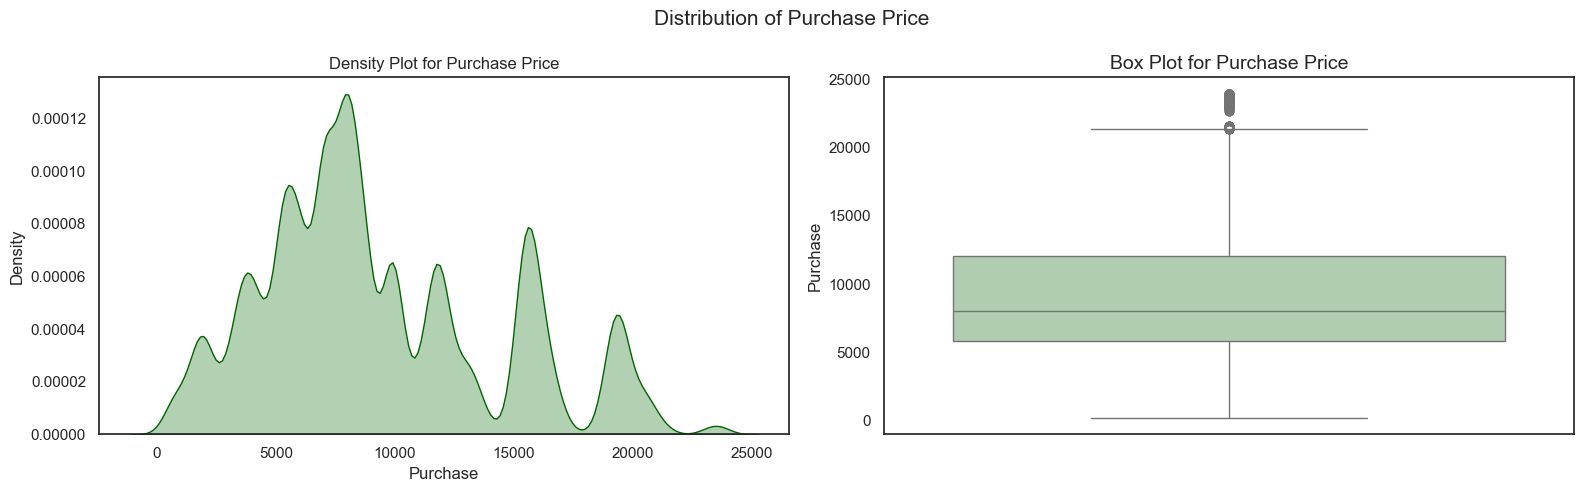

In [54]:
# Creating canvas
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# Density Plot
sns.kdeplot(df['Purchase'], fill=True, color='darkgreen', alpha=0.3, linewidth=1, ax=ax[0])
ax[0].set_title('Density Plot for Purchase Price')

# Box Plot
sns.boxplot(df['Purchase'], color='lightgreen', saturation=0.3, ax=ax[1])
ax[1].set_title('Box Plot for Purchase Price', size=14);

plt.suptitle('Distribution of Purchase Price', size=15)
plt.tight_layout()

**Observation:**

- Purchase price has some **outliers on the right** side of the distribution.

- The Distribution is **slightly skewed to the right (Positive Skew).**

**<h4>Question 10:marital status vs purchase</h4>**



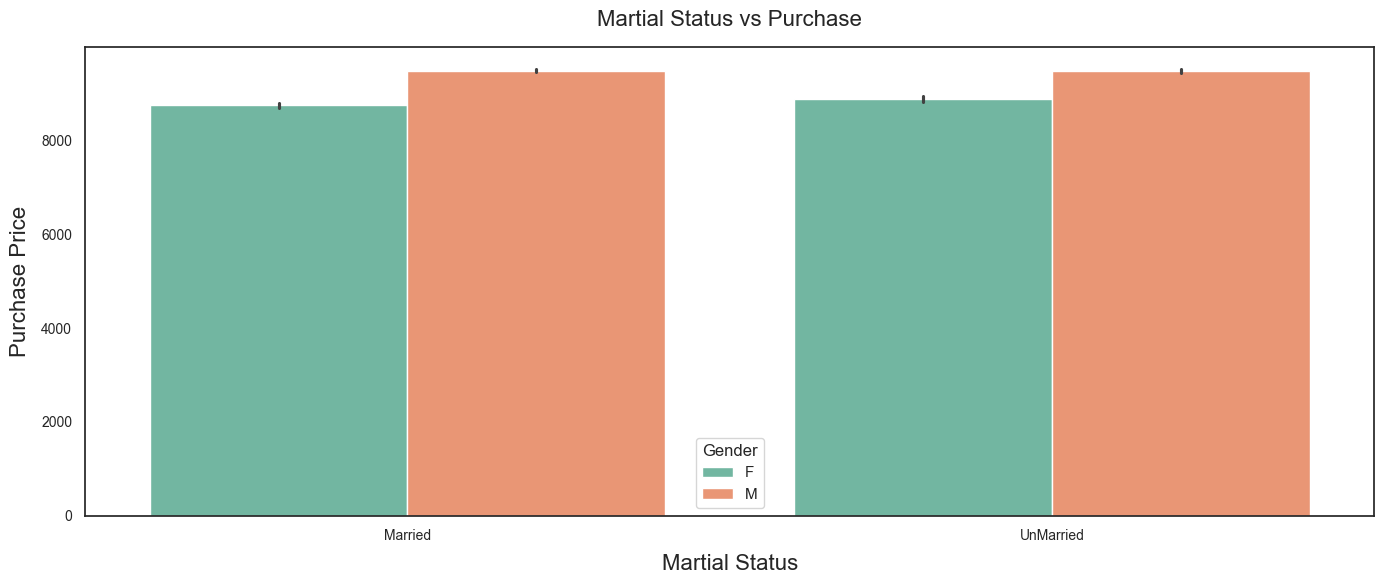

In [55]:
# Creating canvas
fig, ax = plt.subplots(figsize=(14, 6))

# Plotting
sns.barplot(data=df, x='Marital_Status', y='Purchase', hue='Gender', palette='Set2', ax=ax)

# Additional Elements
plt.xlabel('Martial Status', size=16, labelpad=8)
plt.ylabel('Purchase Price', size=16, labelpad=8)
plt.title('Martial Status vs Purchase', size=16, pad=15)
plt.xticks([0,1], ['Married', 'UnMarried'])
plt.tick_params(labelsize=10)

plt.tight_layout()

**Observation:**

- **Regardless of the Martial Status** of the Customers, **Male Purchases are higher** than Female.

- The **Purchase distribution is not much affected by the Martial Status** of the Customer.


**<h4>Question 11: What is the Average Purchases Price based on the Product Category that they buy </h4>**

In [62]:
df

,UserID,ProductID,Gender,Age,Occupation,City_Category,Current_City_Years,Marital_Status,Product_Category,Purchase
0,1000001,P00069042,F,0-17,engineer,A,2,0,3.00000,8370
1,1000001,P00248942,F,0-17,engineer,A,2,0,1.00000,15200
2,1000001,P00087842,F,0-17,engineer,A,2,0,12.00000,1422
3,1000001,P00085442,F,0-17,engineer,A,2,0,12.00000,1057
4,1000002,P00285442,M,55+,Bank Manager,C,4+,0,8.00000,7969
...,...,...,...,...,...,...,...,...,...,...
203272,1001365,P00271142,F,0-17,engineer,C,3,0,5.00000,5210
203273,1001365,P00251242,F,0-17,engineer,C,3,0,5.00000,5385
203274,1001366,P00184942,M,0-17,engineer,C,0,0,1.00000,15573
203275,1001366,P00237642,M,0-17,engineer,C,0,0,5.00000,5262


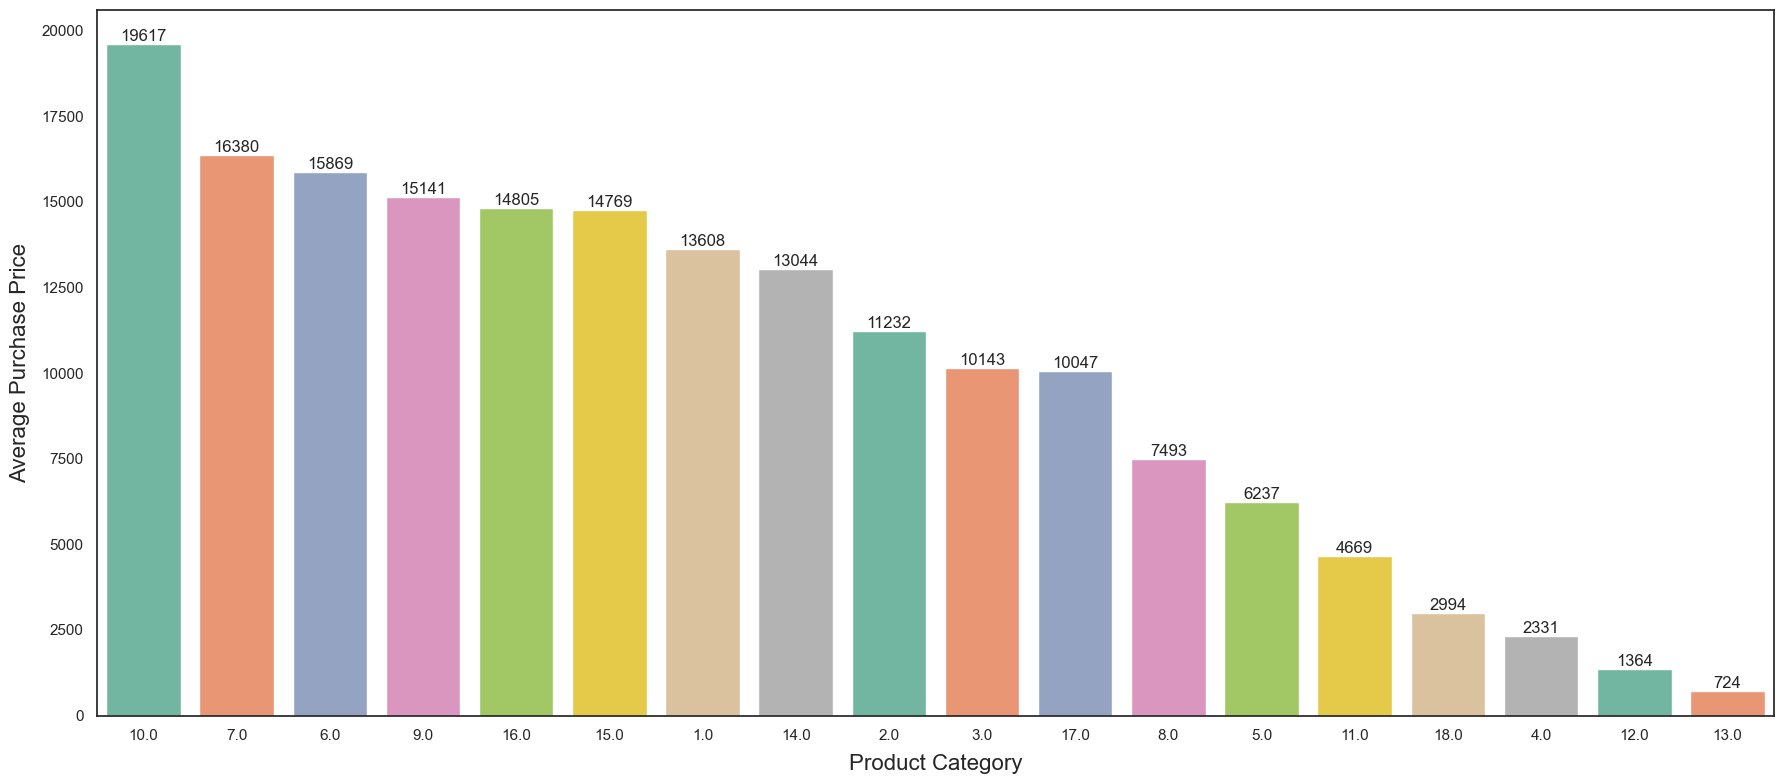

In [68]:
# Creating canvas
fig, ax = plt.subplots(figsize=(18, 8))

# Calculating Avergae Purchase Price
Purchase_Category = (df
                     .groupby('Product_Category')
                     .agg({'Purchase': 'mean'})
                     .reset_index())

# Plot
sns.barplot(x=Purchase_Category.Product_Category, 
            y=Purchase_Category.Purchase,
            palette='Set2', 
            order=Purchase_Category.sort_values('Purchase', ascending=False).Product_Category)

for p in plt.gca().patches:
    x=p.get_bbox().get_points()[:,0]
    y=p.get_bbox().get_points()[1,1]
    value = round(y)
    ax.annotate(text=value, 
                xy=(x.mean(), y),
                ha='center', 
                va='bottom', 
                size=12)

plt.xlabel('Product Category', size=16, labelpad=8)
plt.ylabel('Average Purchase Price', size=16, labelpad=8)
plt.tight_layout()

**Observation:**

- The **Product** with Category **ID 10** have the **Highest Average Purchase Price (19617)**

- The **Product Category 4, 12, and 13** have the **least Average Purchase Price.**


**<h4>Question 12: Which Product Categories are sold more on average based on the gender of the customer? </h4>**

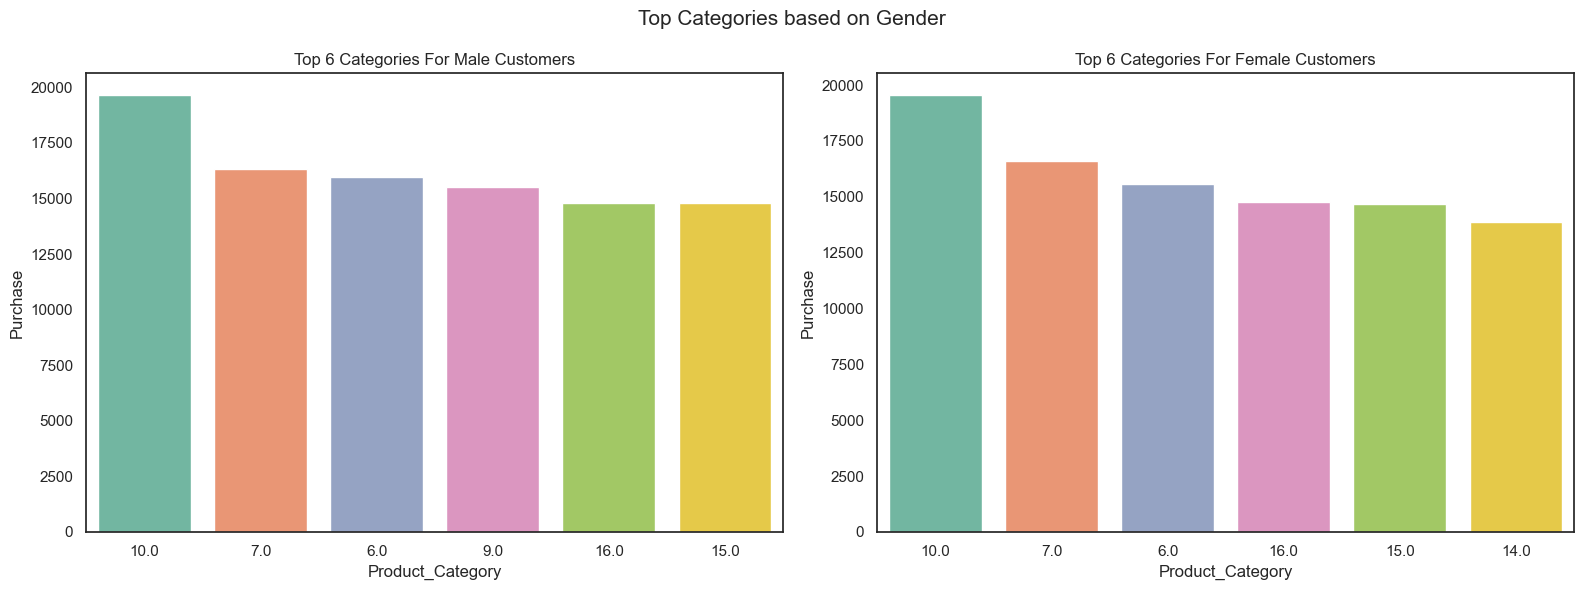

In [73]:
# Calculating Average Purchase Price based on Gender
Male_df = (df
           .groupby(['Gender', 'Product_Category'])
           .agg({'Purchase': 'mean'})
           .loc['M']
           .sort_values('Purchase', ascending=False)
           .iloc[:6,:])
           
Female_df = (df
             .groupby(['Gender', 'Product_Category'])
             .agg({'Purchase': 'mean'})
             .loc['F']
             .sort_values('Purchase', ascending=False)
             .iloc[:6,:])

# Creating canvas
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
plt.suptitle('Top Categories based on Gender', size=15)

# Male
sns.barplot(x=Male_df.index, 
            y=Male_df.Purchase, 
            palette='Set2',
            order=Male_df.sort_values('Purchase', ascending=False).index,
           ax=ax[0])
ax[0].set_title('Top 6 Categories For Male Customers')

# Female
sns.barplot(x=Female_df.index, 
            y=Female_df.Purchase, 
            palette='Set2',
            order=Female_df.sort_values('Purchase', ascending=False).index,
           ax=ax[1])
ax[1].set_title('Top 6 Categories For Female Customers')
plt.tight_layout()

**Observation:**
- Top **6 Categories For Male:**
  - 10, 7, 6, 9, 16, 15
- Top **6 Categories For Female:**
  - 10, 7, 6, 16, 15, 14

- **Product Category 10 is the Customer Favourite** Regardless of the Gender of the Customer

- **5 out of the Top 6 (Namely, 10, 7, 6, 16, 15)** Categories are **same for both Male and Female Customers.**

<a id = Section7></a>

---
# **7. Conclusion**
---

- In our study, we analyzed the **data's characteristics** as well as its distribution in depth.

- In this EDA, we examined various questions related to **customer behavior** and **buying habits**.

- Customer purchase patterns were plotted and **observations** were made using **city, marital status, occupation, and age data**

- From the EDA we can conclude that:

  - The number of purchases made by **men** on ECOMM is **higher** than that of **women**.
 - The **average** purchase price is between **₹5000 - ₹10000**.
 - Around **42%** of site visits come from **city B**
 - **68%** of the site visitors are aged between **26-50**


**Actionable Insights**

- Considering that people over the age of 50 spend more money, ECOMM can offer **discounts** to other age categories to **increase revenue**.

- Add more **delivery partners** to **city B** to ensure **prompt delivery** of products during the **big billion-day sale**

- Stock up on the **top 10 selling** products, as well as items priced between **5000 and 10000 rupees**

- **Personalized offer** can be given to customer based on their gender on products of the top categories for that gender.
  - Top **6 Categories For Male:** 10, 7, 6, 9, 16, 15
  - Top **6 Categories For Female:** 10, 7, 6, 16, 15, 14

- To balance **gender shopping ratios** and **increase female** customer numbers, give discounts on **women's products** and give **offers** to individuals who are working as **Aerospace Engineers, Doctors, and Judge**.